# ==============================================================================
# BÀI TẬP 2: DEEP CONVOLUTIONAL GAN (DCGAN) & KHẮC PHỤC MODE COLLAPSE
# ==============================================================================

### 🎯 Mục tiêu bài học:
1. **Quy chuẩn kiến trúc DCGAN (Radford et al., 2015):**
   * Thay thế hoàn toàn Pooling bằng Strided Convolutions ($D$) và Fractionally-strided Convolutions ($G$).
   * Áp dụng Batch Normalization ở cả hai mạng (loại trừ tầng vào của $D$ và tầng ra của $G$).
   * Hàm kích hoạt: $G$ dùng ReLU + Tanh; $D$ dùng LeakyReLU(0.2) xuyên suốt.
2. **Khởi tạo trọng số chuẩn hóa:** Khởi tạo các tham số theo $\mathcal{N}(0, 0.02)$.
3. **Kỹ thuật Label Smoothing:** Gán nhãn ảnh thật là $0.9$ thay vì $1.0$ cho $D$ nhằm ngăn chặn Discriminator quá tự tin dẫn đến vanishing gradient.
4. **Thực nghiệm hiện tượng Mode Collapse:** Cố tình loại bỏ BatchNorm và tăng cường sức mạnh $D$ để ép mạng sụp đổ vào một mode duy nhất, sau đó đối chiếu trực diện với DCGAN chuẩn.

In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

# Cố định seed
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Thiết bị thực thi: {device}")

[+] Thiết bị thực thi: cuda


In [2]:
# ==============================================================================
# 1. CHUẨN BỊ DỮ LIỆU CIFAR-10 (RESIZE 64x64)
# Chuẩn hóa về [-1, 1] trên 3 kênh RGB
# ==============================================================================
IMAGE_SIZE = 64
transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

full_dataset = datasets.CIFAR10(root="./data", train=True, download=False, transform=transform)
# Sử dụng tập con 10.000 mẫu để thực nghiệm vừa nhanh vừa đảm bảo tính hội tụ
subset_indices = list(range(10000))
train_dataset = Subset(full_dataset, subset_indices)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, drop_last=True)

print(f"[+] Số lượng ảnh huấn luyện: {len(train_dataset):,} mẫu (kích thước {IMAGE_SIZE}x{IMAGE_SIZE}x3)")

[+] Số lượng ảnh huấn luyện: 10,000 mẫu (kích thước 64x64x3)


In [3]:
# ==============================================================================
# 2. QUY CHUẨN KIẾN TRÚC DCGAN & HÀM KHỞI TẠO TRỌNG SỐ (Radford et al.)
# ==============================================================================

def weights_init(m):
    """Khởi tạo trọng số theo phân phối chuẩn N(0, 0.02) như bài báo DCGAN gốc"""
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


class DCGAN_Generator(nn.Module):
    """
    Generator chuẩn DCGAN (64x64):
    Fractionally-strided Convolutions (ConvTranspose2d) + BatchNorm2d + ReLU -> Tanh
    """
    def __init__(self, nz=100, ngf=64, nc=3, use_bn=True):
        super().__init__()
        layers = []
        # Khối 1: z in R^100 -> (ngf*8) x 4 x 4
        layers.append(nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False))
        if use_bn: layers.append(nn.BatchNorm2d(ngf * 8))
        layers.append(nn.ReLU(True))
        
        # Khối 2: (ngf*8) x 4 x 4 -> (ngf*4) x 8 x 8
        layers.append(nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False))
        if use_bn: layers.append(nn.BatchNorm2d(ngf * 4))
        layers.append(nn.ReLU(True))
        
        # Khối 3: (ngf*4) x 8 x 8 -> (ngf*2) x 16 x 16
        layers.append(nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False))
        if use_bn: layers.append(nn.BatchNorm2d(ngf * 2))
        layers.append(nn.ReLU(True))
        
        # Khối 4: (ngf*2) x 16 x 16 -> ngf x 32 x 32
        layers.append(nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False))
        if use_bn: layers.append(nn.BatchNorm2d(ngf))
        layers.append(nn.ReLU(True))
        
        # Khối 5: ngf x 32 x 32 -> nc x 64 x 64 (Không đặt BatchNorm ở tầng ra!)
        layers.append(nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False))
        layers.append(nn.Tanh())
        self.main = nn.Sequential(*layers)

    def forward(self, x):
        return self.main(x)


class DCGAN_Discriminator(nn.Module):
    """
    Discriminator chuẩn DCGAN (64x64):
    Strided Convolutions (Conv2d) + BatchNorm2d + LeakyReLU(0.2) -> 1 logit
    """
    def __init__(self, nc=3, ndf=64):
        super().__init__()
        self.main = nn.Sequential(
            # Khối 1: nc x 64 x 64 -> ndf x 32 x 32 (Không đặt BatchNorm ở tầng vào!)
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            # Khối 2: ndf x 32 x 32 -> (ndf*2) x 16 x 16
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            
            # Khối 3: (ndf*2) x 16 x 16 -> (ndf*4) x 8 x 8
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            
            # Khối 4: (ndf*4) x 8 x 8 -> (ndf*8) x 4 x 4
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            
            # Khối 5: (ndf*8) x 4 x 4 -> 1 x 1 x 1
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False)
        )

    def forward(self, x):
        return self.main(x).view(-1, 1)

fixed_noise = torch.randn(64, 100, 1, 1, device=device)
print("[+] Đã hoàn thành định nghĩa kiến trúc DCGAN và hàm weights_init!")

[+] Đã hoàn thành định nghĩa kiến trúc DCGAN và hàm weights_init!


In [4]:
# ==============================================================================
# 3. THỰC NGHIỆM A: DCGAN CHUẨN + KỸ THUẬT LABEL SMOOTHING (NHÃN THẬT = 0.9)
# ==============================================================================
print("=" * 70)
print("THỰC NGHIỆM A: HUẤN LUYỆN DCGAN CHUẨN + LABEL SMOOTHING (15 EPOCHS)")
print("=" * 70)

netG_A = DCGAN_Generator(nz=100, ngf=64, nc=3, use_bn=True).to(device)
netD_A = DCGAN_Discriminator(nc=3, ndf=64).to(device)
netG_A.apply(weights_init)
netD_A.apply(weights_init)

criterion = nn.BCEWithLogitsLoss()
optG_A = torch.optim.Adam(netG_A.parameters(), lr=0.0002, betas=(0.5, 0.999))
optD_A = torch.optim.Adam(netD_A.parameters(), lr=0.0002, betas=(0.5, 0.999))

EPOCHS = 15
losses_D_A, losses_G_A = [], []

for epoch in range(1, EPOCHS + 1):
    netD_A.train()
    netG_A.train()
    total_d, total_g = 0.0, 0.0

    for real_imgs, _ in train_loader:
        b_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)

        # Label Smoothing: Nhãn ảnh thật là 0.9 thay vì 1.0!
        label_real = torch.full((b_size, 1), 0.9, device=device)
        label_fake = torch.full((b_size, 1), 0.0, device=device)

        # --- Train Discriminator ---
        optD_A.zero_grad()
        out_real = netD_A(real_imgs)
        loss_d_real = criterion(out_real, label_real)

        noise = torch.randn(b_size, 100, 1, 1, device=device)
        fake_imgs = netG_A(noise)
        out_fake = netD_A(fake_imgs.detach())
        loss_d_fake = criterion(out_fake, label_fake)

        loss_D = loss_d_real + loss_d_fake
        loss_D.backward()
        optD_A.step()
        total_d += loss_D.item()

        # --- Train Generator (Nonsaturating game) ---
        optG_A.zero_grad()
        # Generator muốn D phân loại ảnh giả thành 1.0
        label_g = torch.full((b_size, 1), 1.0, device=device)
        out_g = netD_A(fake_imgs)
        loss_G = criterion(out_g, label_g)
        loss_G.backward()
        optG_A.step()
        total_g += loss_G.item()

    avg_d = total_d / len(train_loader)
    avg_g = total_g / len(train_loader)
    losses_D_A.append(avg_d)
    losses_G_A.append(avg_g)
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Loss D: {avg_d:.4f} | Loss G: {avg_g:.4f}")

netG_A.eval()
with torch.no_grad():
    samples_dcgan = netG_A(fixed_noise).cpu()
    samples_dcgan = (samples_dcgan + 1.0) / 2.0
print("[+] Hoàn thành Thực nghiệm A!")

THỰC NGHIỆM A: HUẤN LUYỆN DCGAN CHUẨN + LABEL SMOOTHING (15 EPOCHS)


Epoch [01/15] | Loss D: 1.0041 | Loss G: 11.5482


Epoch [02/15] | Loss D: 0.8243 | Loss G: 4.1363


Epoch [03/15] | Loss D: 0.7090 | Loss G: 5.0222


Epoch [04/15] | Loss D: 0.5341 | Loss G: 5.4183


...

Epoch [11/15] | Loss D: 0.9112 | Loss G: 3.1655


Epoch [12/15] | Loss D: 0.8651 | Loss G: 3.3026


Epoch [13/15] | Loss D: 0.8356 | Loss G: 3.3505


Epoch [14/15] | Loss D: 0.8170 | Loss G: 3.5614


Epoch [15/15] | Loss D: 0.8189 | Loss G: 3.4809
[+] Hoàn thành Thực nghiệm A!


In [5]:
# ==============================================================================
# 4. THỰC NGHIỆM B: TÁI HIỆN HIỆN TƯỢNG MODE COLLAPSE
# Thiết kế: Bỏ BatchNorm trong Generator + Huấn luyện D quá mạnh (lr_D gấp 5 lần)
# ==============================================================================
print("=" * 70)
print("THỰC NGHIỆM B: ÉP MÔ HÌNH RƠI VÀO TRẠNG THÁI MODE COLLAPSE")
print("=" * 70)

# Generator không có BatchNorm (use_bn=False)
netG_B = DCGAN_Generator(nz=100, ngf=64, nc=3, use_bn=False).to(device)
netD_B = DCGAN_Discriminator(nc=3, ndf=64).to(device)
netG_B.apply(weights_init)
netD_B.apply(weights_init)

# Tăng learning rate của D lên 0.001 (gấp 5 lần G) và không dùng Label Smoothing (nhãn cứng 1.0 / 0.0)
optD_B = torch.optim.Adam(netD_B.parameters(), lr=0.001, betas=(0.5, 0.999))
optG_B = torch.optim.Adam(netG_B.parameters(), lr=0.0002, betas=(0.5, 0.999))

losses_D_B, losses_G_B = [], []

for epoch in range(1, EPOCHS + 1):
    netD_B.train()
    netG_B.train()
    total_d, total_g = 0.0, 0.0

    for real_imgs, _ in train_loader:
        b_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)

        label_real = torch.full((b_size, 1), 1.0, device=device)
        label_fake = torch.full((b_size, 1), 0.0, device=device)

        # Huấn luyện D 2 bước cho mỗi 1 bước G
        for _ in range(2):
            optD_B.zero_grad()
            out_real = netD_B(real_imgs)
            loss_d_real = criterion(out_real, label_real)

            noise = torch.randn(b_size, 100, 1, 1, device=device)
            fake_imgs = netG_B(noise)
            out_fake = netD_B(fake_imgs.detach())
            loss_d_fake = criterion(out_fake, label_fake)

            loss_D = loss_d_real + loss_d_fake
            loss_D.backward()
            optD_B.step()
        total_d += loss_D.item()

        # Huấn luyện G
        optG_B.zero_grad()
        out_g = netD_B(fake_imgs)
        loss_G = criterion(out_g, label_real)
        loss_G.backward()
        optG_B.step()
        total_g += loss_G.item()

    avg_d = total_d / len(train_loader)
    avg_g = total_g / len(train_loader)
    losses_D_B.append(avg_d)
    losses_G_B.append(avg_g)
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Loss D: {avg_d:.4f} | Loss G: {avg_g:.4f}")

netG_B.eval()
with torch.no_grad():
    samples_collapse = netG_B(fixed_noise).cpu()
    samples_collapse = (samples_collapse + 1.0) / 2.0
print("[+] Hoàn thành Thực nghiệm B (Mode Collapse)!")

THỰC NGHIỆM B: ÉP MÔ HÌNH RƠI VÀO TRẠNG THÁI MODE COLLAPSE


Epoch [01/15] | Loss D: 0.3457 | Loss G: 21.5039


Epoch [02/15] | Loss D: 0.0948 | Loss G: 10.3569


Epoch [03/15] | Loss D: 0.2927 | Loss G: 6.8087


Epoch [04/15] | Loss D: 0.2323 | Loss G: 5.4962


...

Epoch [11/15] | Loss D: 0.3585 | Loss G: 5.6834


Epoch [12/15] | Loss D: 0.3566 | Loss G: 5.8168


Epoch [13/15] | Loss D: 0.4319 | Loss G: 5.9817


Epoch [14/15] | Loss D: 0.5383 | Loss G: 4.7635


Epoch [15/15] | Loss D: 0.5680 | Loss G: 4.4551
[+] Hoàn thành Thực nghiệm B (Mode Collapse)!


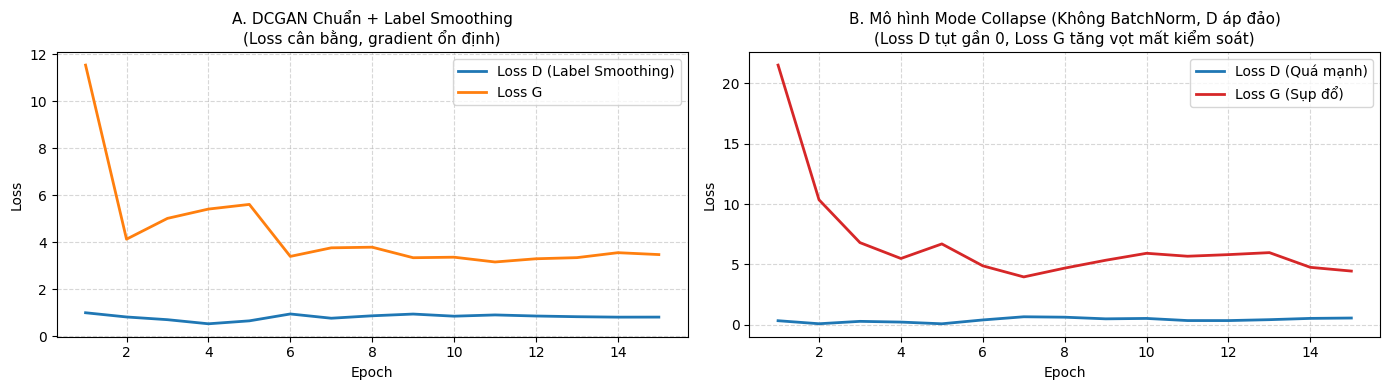

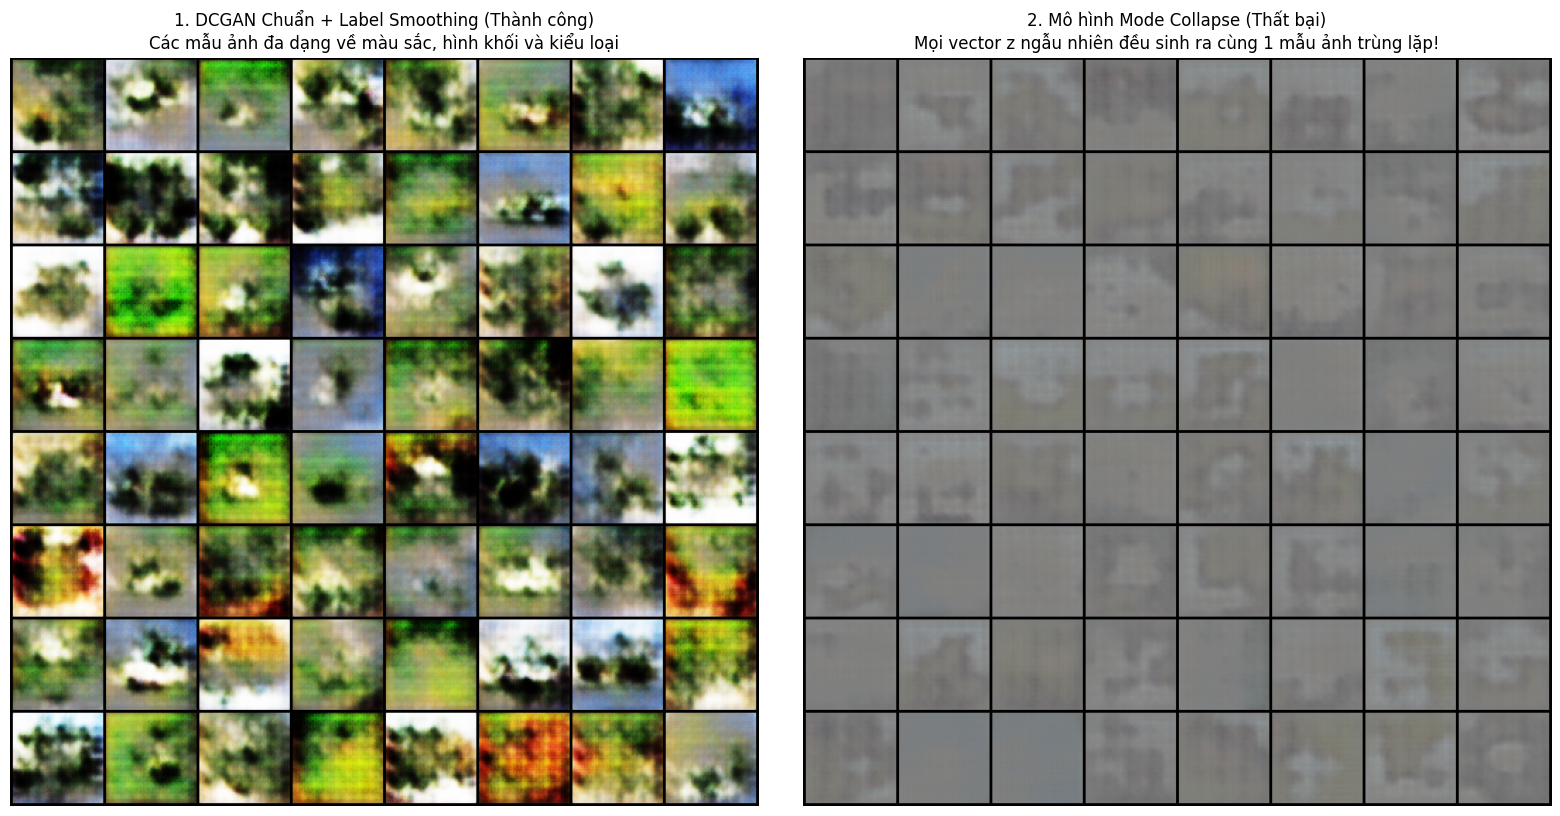

In [6]:
# ==============================================================================
# 5. TRỰC QUAN HÓA SO SÁNH TRỰC DIỆN: DCGAN CHUẨN VS. MODE COLLAPSE
# ==============================================================================

# 1. So sánh đồ thị hàm mất mát
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(range(1, EPOCHS + 1), losses_D_A, label="Loss D (Label Smoothing)", color="tab:blue", lw=2)
axes[0].plot(range(1, EPOCHS + 1), losses_G_A, label="Loss G", color="tab:orange", lw=2)
axes[0].set_title("A. DCGAN Chuẩn + Label Smoothing\n(Loss cân bằng, gradient ổn định)", fontsize=11)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(range(1, EPOCHS + 1), losses_D_B, label="Loss D (Quá mạnh)", color="tab:blue", lw=2)
axes[1].plot(range(1, EPOCHS + 1), losses_G_B, label="Loss G (Sụp đổ)", color="tab:red", lw=2)
axes[1].set_title("B. Mô hình Mode Collapse (Không BatchNorm, D áp đảo)\n(Loss D tụt gần 0, Loss G tăng vọt mất kiểm soát)", fontsize=11)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 2. So sánh ảnh sinh ra trên lưới 64 mẫu cố định
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

grid_a = make_grid(samples_dcgan[:64], nrow=8, padding=2)
axes[0].imshow(grid_a.permute(1, 2, 0).numpy())
axes[0].set_title("1. DCGAN Chuẩn + Label Smoothing (Thành công)\nCác mẫu ảnh đa dạng về màu sắc, hình khối và kiểu loại", fontsize=12)
axes[0].axis("off")

grid_b = make_grid(samples_collapse[:64], nrow=8, padding=2)
axes[1].imshow(grid_b.permute(1, 2, 0).numpy())
axes[1].set_title("2. Mô hình Mode Collapse (Thất bại)\nMọi vector z ngẫu nhiên đều sinh ra cùng 1 mẫu ảnh trùng lặp!", fontsize=12)
axes[1].axis("off")

plt.tight_layout()
plt.show()

# ==============================================================================
# 6. BÁO CÁO PHÂN TÍCH: MODE COLLAPSE & KỸ THUẬT LABEL SMOOTHING
# ==============================================================================

### 1. Hiện tượng Mode Collapse (Sụp đổ Mode) là gì?
* **Định nghĩa:** Mode Collapse là hiện tượng Generator chỉ tập trung học và sinh ra một số lượng rất ít các mẫu dữ liệu (thậm chí chỉ 1 mẫu duy nhất) đánh lừa được Discriminator tốt nhất, thay vì bao phủ toàn bộ phân phối đa dạng của dữ liệu thật (xe hơi, máy bay, chó, mèo...).
* **Quan sát thực nghiệm:**
  * Trong Thực nghiệm B, khi loại bỏ Batch Normalization trong $G$ và để $D$ học quá mạnh ($lr = 0.001$, cập nhật 2 lượt), $D$ nhanh chóng ép chặt không gian nghiệm khiến $Loss_D \to 0$.
  * $G$ phát hiện một "lỗ hổng" cục bộ trong không gian đặc trưng của $D$ và dồn toàn bộ trọng số để ánh xạ tất cả các vector nhiễu $z$ về đúng tọa độ đó. Kết quả trên lưới $8 \times 8$, toàn bộ 64 ô hiển thị một bức ảnh giống hệt nhau.

### 2. Tác dụng của kỹ thuật Label Smoothing ($0.9$ thay vì $1.0$):
* **Vấn đề của nhãn cứng (Hard Labels 1.0):** Khi gán nhãn ảnh thật là $1.0$, Discriminator có xu hướng đẩy logit ra cực xa ($\to +\infty$) để xác suất đạt gần $100\%$. Khi logit quá lớn, đạo hàm của hàm Sigmoid $\sigma'(x) = \sigma(x)(1 - \sigma(x)) \to 0$, khiến gradient truyền ngược về Generator bị tắt hoàn toàn.
* **One-sided Label Smoothing:** Gán nhãn ảnh thật bằng $0.9$ (và giữ nguyên nhãn ảnh giả là $0.0$ theo đúng lý thuyết Szegedy et al. & Salimans et al.).
  * Ngăn cản $D$ quá tự tin (overconfident).
  * Giữ logit ở phạm vi hữu hạn vừa phải, đảm bảo luồng gradient ổn định và dồi dào liên tục truyền ngược về Generator qua từng batch.

### 3. Vai trò sống còn của Batch Normalization trong DCGAN:
* Giúp chuẩn hóa phân phối đầu ra của mỗi tầng về mean $= 0$ và variance $= 1$, ngăn chặn tình trạng toàn bộ gradient bị lệch về một hướng đơn lẻ.
* Đóng vai trò là một lớp điều hòa (regularizer) giúp thông tin gradient lan tỏa đều trên toàn bộ chiều của không gian tiềm ẩn $z$, ngăn không cho Generator bị sụp đổ vào 1 mode duy nhất.